In [127]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 

In [128]:
ford=pd.read_csv("ford.csv")

In [129]:
ford.head()

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
0,Fiesta,2017,12000,Automatic,15944,Petrol,150,57.7,1.0
1,Focus,2018,14000,Manual,9083,Petrol,150,57.7,1.0
2,Focus,2017,13000,Manual,12456,Petrol,150,57.7,1.0
3,Fiesta,2019,17500,Manual,10460,Petrol,145,40.3,1.5
4,Fiesta,2019,16500,Automatic,1482,Petrol,145,48.7,1.0


In [130]:
ford.isnull().sum()

model           0
year            0
price           0
transmission    0
mileage         0
fuelType        0
tax             0
mpg             0
engineSize      0
dtype: int64

In [131]:
ford.describe()

,year,price,mileage,tax,mpg,engineSize
count,17966.000000,17966.000000,17966.000000,17966.000000,17966.000000,17966.000000
mean,2016.866470,12279.534844,23362.608761,113.329456,57.906980,1.350807
std,2.050336,4741.343657,19472.054349,62.012456,10.125696,0.432367
min,1996.000000,495.000000,1.000000,0.000000,20.800000,0.000000
25%,2016.000000,8999.000000,9987.000000,30.000000,52.300000,1.000000
50%,2017.000000,11291.000000,18242.500000,145.000000,58.900000,1.200000
75%,2018.000000,15299.000000,31060.000000,145.000000,65.700000,1.500000
max,2060.000000,54995.000000,177644.000000,580.000000,201.800000,5.000000


In [132]:
ford.head()

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
0,Fiesta,2017,12000,Automatic,15944,Petrol,150,57.7,1.0
1,Focus,2018,14000,Manual,9083,Petrol,150,57.7,1.0
2,Focus,2017,13000,Manual,12456,Petrol,150,57.7,1.0
3,Fiesta,2019,17500,Manual,10460,Petrol,145,40.3,1.5
4,Fiesta,2019,16500,Automatic,1482,Petrol,145,48.7,1.0


In [133]:
ford["transmission"].value_counts()

transmission
Manual       15518
Automatic     1361
Semi-Auto     1087
Name: count, dtype: int64

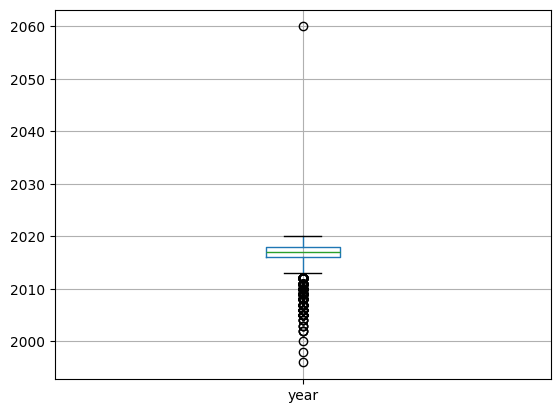

In [134]:
ford.boxplot(column=['year'])
plt.show()

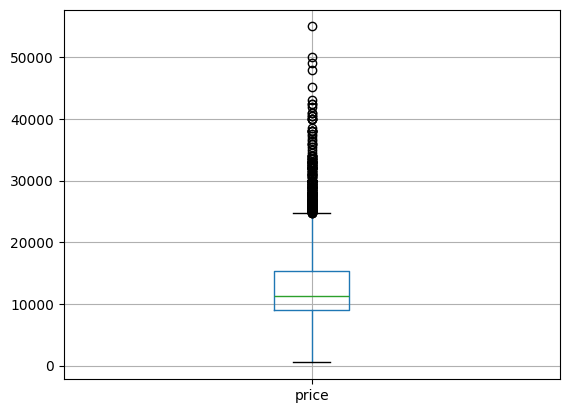

In [135]:
ford.boxplot(column=["price"])
plt.show()

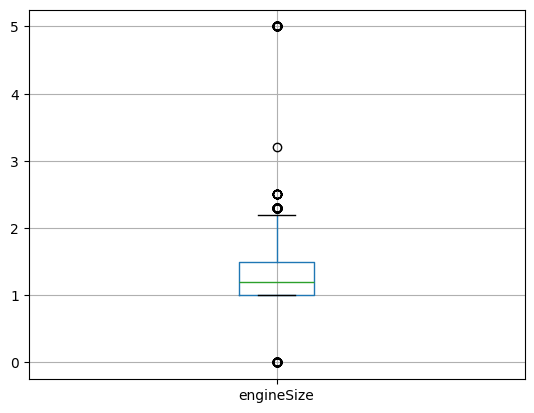

In [136]:
ford.boxplot(column=['engineSize'])
plt.show()

In [137]:

columns_to_clip = ['year', 'price', 'mileage', 'tax', 'mpg', 'engineSize']

for col in columns_to_clip:
    Q1 = ford[col].quantile(0.25)
    Q3 = ford[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

   
    ford[col] = ford[col].clip(lower=lower_bound, upper=upper_bound)


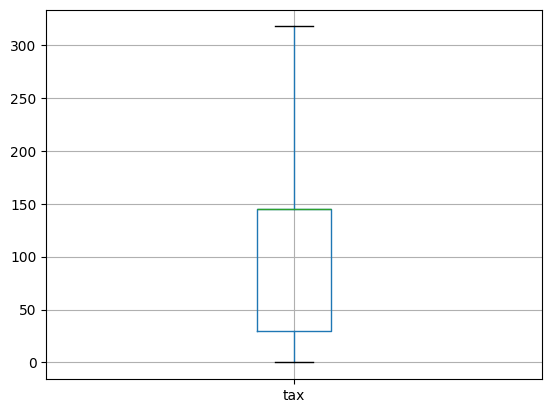

In [138]:
ford.boxplot(column=['tax'])
plt.show()


In [139]:
from sklearn.model_selection import train_test_split

In [140]:
x=ford.drop(columns=["model","price"])
y=ford["price"]

In [141]:
x_train,x_test,y_train,Y_test=train_test_split(
    x,y,test_size=0.2,random_state=0
)

In [142]:
x_train

,year,transmission,mileage,fuelType,tax,mpg,engineSize
3257,2018,Manual,8169.0,Petrol,145.0,53.3,1.0
14537,2013,Manual,62669.5,Petrol,30.0,57.7,1.2
4436,2017,Manual,20962.0,Petrol,125.0,53.3,1.0
14091,2016,Manual,32000.0,Petrol,0.0,65.7,1.0
94,2015,Manual,47904.0,Diesel,125.0,56.5,1.6
...,...,...,...,...,...,...,...
9225,2016,Manual,53530.0,Diesel,0.0,74.3,1.5
13123,2017,Semi-Auto,26806.0,Petrol,160.0,44.1,1.6
9845,2015,Manual,18136.0,Diesel,0.0,85.8,1.5
10799,2018,Manual,10435.0,Diesel,145.0,54.3,1.5


In [143]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler

In [144]:
transformer=ColumnTransformer(transformers=[
    ("tnf1",OrdinalEncoder(categories=[["Manual","Automatic","Semi-Auto"]]),["transmission"]),
    ("tnf2",OneHotEncoder(sparse_output=False,drop='first'),["fuelType"]),
    ("tnf3",StandardScaler(),['year', 'mileage', 'tax', 'mpg'])
],remainder="passthrough"
)

In [145]:
x_train_tran=transformer.fit_transform(x_train)

In [146]:
x_test_tran=transformer.transform(x_test)

In [147]:
new_columns = transformer.get_feature_names_out()

In [148]:
x_train_tran=pd.DataFrame(x_train_tran,columns=new_columns)

In [149]:
x_test_tran=pd.DataFrame(x_test_tran,columns=new_columns)

In [150]:
from sklearn.linear_model import LinearRegression


In [151]:
model=LinearRegression()
model.fit(x_train_tran,y_train)


,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [152]:
y_pred = model.predict(x_test_tran)

In [153]:
from sklearn.metrics import r2_score
print("R2 Score:", r2_score(Y_test, y_pred))

R2 Score: 0.7658347003376245


In [154]:
x_train_tran.head()

,tnf1__transmission,tnf2__fuelType_Electric,tnf2__fuelType_Hybrid,tnf2__fuelType_Other,tnf2__fuelType_Petrol,tnf3__year,tnf3__mileage,tnf3__tax,tnf3__mpg,remainder__engineSize
0,0.0,0.0,0.0,0.0,1.0,0.619072,-0.870156,0.524355,-0.476122,1.0
1,0.0,0.0,0.0,0.0,1.0,-2.313653,2.432108,-1.345746,-0.023363,1.2
2,0.0,0.0,0.0,0.0,1.0,0.032527,-0.095010,0.199120,-0.476122,1.0
3,0.0,0.0,0.0,0.0,1.0,-0.554018,0.573799,-1.833598,0.799835,1.0
4,0.0,0.0,0.0,0.0,0.0,-1.140563,1.537445,0.199120,-0.146843,1.6


In [155]:
from sklearn.neighbors import KNeighborsRegressor

In [159]:
knn=KNeighborsRegressor()
knn.fit(x_train_tran,y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [160]:
y_pred_knn=knn.predict(x_test_tran)

In [161]:
print("R2 Score:", r2_score(Y_test, y_pred_knn))

R2 Score: 0.8937215715369135


In [162]:
from sklearn.svm import SVR

In [163]:
 svr=SVR()
svr.fit(x_train_tran,y_train)

,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,tol,0.001
,C,1.0
,epsilon,0.1
,shrinking,True
,cache_size,200
,verbose,False
,max_iter,-1


In [165]:
y_pred_svr=svr.predict(x_test_tran)

In [167]:
print("R2 Score:", r2_score(Y_test, y_pred_svr))

R2 Score: 0.2018316382671037
